# Exploratory Data Analysis: Steam Game Recommendations

Dataset: [Game Recommendations on Steam](https://www.kaggle.com/datasets/antonkozyriev/game-recommendations-on-steam) (Kaggle).

The goal is a **top-N recommender**: given a user's review history, rank the games they are most likely to enjoy.
The reviews file has ~41M rows, so this notebook works on a deterministic 5% sample of users and keeps only
users with at least 3 reviews and games with at least 20 reviews.


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [32]:
# Raw Kaggle files; override with BASE_PATH or the per-file variables
BASE = os.environ.get('BASE_PATH', '../data/raw')
GAMES_PATH = os.environ.get('GAMES_DATA_PATH', f'{BASE}/games.csv')
RECOMMENDATIONS_PATH = os.environ.get('RECOMMENDATIONS_DATA_PATH', f'{BASE}/recommendations.csv')
USERS_PATH = os.environ.get('USERS_DATA_PATH', f'{BASE}/users.csv')
METADATA_PATH = os.environ.get('METADATA_DATA_PATH', f'{BASE}/games_metadata.json')

# Config
USER_MOD = 20          # keep users where user_id % 20 == 0  -> 5% of users
MIN_USER_REVIEWS = 3
MIN_GAME_REVIEWS = 20

# Games
games = pd.read_csv(GAMES_PATH)

# Recommendations: sample USERS, keep ALL of their review
chunks = []
for chunk in pd.read_csv(RECOMMENDATIONS_PATH, chunksize=1_000_000):
    chunks.append(chunk[chunk['user_id'] % USER_MOD == 0])
recommendations = pd.concat(chunks, ignore_index=True)
print(f"After user sampling: {recommendations.shape}")

# Filter sparse users/games
for _ in range(3):
    user_counts = recommendations['user_id'].value_counts()
    recommendations = recommendations[
        recommendations['user_id'].isin(user_counts[user_counts >= MIN_USER_REVIEWS].index)
    ]
    game_counts = recommendations['app_id'].value_counts()
    recommendations = recommendations[
        recommendations['app_id'].isin(game_counts[game_counts >= MIN_GAME_REVIEWS].index)
    ]
recommendations = recommendations.reset_index(drop=True)

print(f"After filtering: {recommendations.shape}")
print(f"Users: {recommendations['user_id'].nunique():,} | Games: {recommendations['app_id'].nunique():,}")
print(f"Avg reviews/user: {len(recommendations) / recommendations['user_id'].nunique():.2f}")

# Users: keep only those in the sample
sampled_user_ids = set(recommendations['user_id'].unique())
users = pd.concat(
    [c[c['user_id'].isin(sampled_user_ids)] for c in pd.read_csv(USERS_PATH, chunksize=500_000)],
    ignore_index=True
)

# Games: keep only those that survived filtering
games = games[games['app_id'].isin(recommendations['app_id'].unique())].reset_index(drop=True)

# Metadata (tags + description) -> essential for content-based KNN
metadata = pd.read_json(METADATA_PATH, lines=True)
metadata = metadata[metadata['app_id'].isin(games['app_id'])].reset_index(drop=True)

print(f"Games: {games.shape} | Users: {users.shape} | Metadata: {metadata.shape}")

After user sampling: (2058217, 8)
After filtering: (1332555, 8)
Users: 182,790 | Games: 5,711
Avg reviews/user: 7.29
Games: (5711, 13) | Users: (160095, 3) | Metadata: (5711, 3)


## 1. Structural Overview: Shape & Data Types

In [33]:
print(f"Games shape: {games.shape}")
print(f"Recommendations shape: {recommendations.shape}")
print(f"Users shape: {users.shape}")

print("\n--- Games Columns & Types ---")
games.info()

print("\n--- Recommendations Columns & Types ---")
recommendations.info()

print("\n--- Users Columns & Types ---")
users.info()

Games shape: (5711, 13)
Recommendations shape: (1332555, 8)
Users shape: (160095, 3)

--- Games Columns & Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5711 entries, 0 to 5710
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   app_id          5711 non-null   int64  
 1   title           5711 non-null   object 
 2   date_release    5711 non-null   object 
 3   win             5711 non-null   bool   
 4   mac             5711 non-null   bool   
 5   linux           5711 non-null   bool   
 6   rating          5711 non-null   object 
 7   positive_ratio  5711 non-null   int64  
 8   user_reviews    5711 non-null   int64  
 9   price_final     5711 non-null   float64
 10  price_original  5711 non-null   float64
 11  discount        5711 non-null   float64
 12  steam_deck      5711 non-null   bool   
dtypes: bool(4), float64(3), int64(3), object(3)
memory usage: 424.0+ KB

--- Recommendations Columns 

In [34]:
games.sample(5)

,app_id,title,date_release,win,mac,linux,rating,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck
5082,610180,The Jackbox Party Pack 4,2017-10-18,True,True,True,Very Positive,94,2019,24.99,24.99,0.0,True
2514,270880,American Truck Simulator,2016-02-02,True,True,True,Overwhelmingly Positive,96,108202,20.00,0.00,0.0,True
5144,714010,Aimlabs,2023-06-16,True,False,False,Very Positive,93,89133,0.00,0.00,0.0,True
2315,989440,Phantom Abyss,2021-06-21,True,False,False,Very Positive,86,1713,24.99,24.99,0.0,True
4441,457330,High Octane Drift,2016-10-14,True,False,False,Mixed,55,5913,0.00,0.00,0.0,True


In [35]:
recommendations.sample(5)

,app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
615406,380,0,0,2020-03-25,True,3.7,6563020,19249750
1058327,884660,0,0,2018-09-06,True,7.0,10164400,32416678
265012,55150,0,0,2021-01-17,True,1.0,8546180,9234861
824655,916440,0,0,2019-04-16,True,11.2,7469540,25369354
1178407,269190,5,0,2018-12-10,False,1.6,10329820,35884715


In [36]:
users.sample(5)

,user_id,products,reviews
35703,11953840,942.0,3.0
122778,2837860,164.0,3.0
107881,14249320,25.0,4.0
66533,12968760,125.0,24.0
76679,13665380,10.0,4.0


## 2. Completeness: Checking Missing Values

In [37]:
print("Missing Values in Games:")
display(games.isnull().sum())

print("\nMissing Values in Recommendations:")
display(recommendations.isnull().sum())

print("\nMissing Values in Users:")
display(users.isnull().sum())

Missing Values in Games:


,0
app_id,0
title,0
date_release,0
win,0
mac,0
linux,0
rating,0
positive_ratio,0
user_reviews,0
price_final,0



Missing Values in Recommendations:


,0
app_id,0
helpful,0
funny,0
date,0
is_recommended,0
hours,0
user_id,0
review_id,0



Missing Values in Users:


,0
user_id,0
products,0
reviews,0


## 3. Uniqueness: Duplicate Entries and Class Imbalance

In [38]:
print(f"Duplicate rows in Games: {games.duplicated().sum()}")
print(f"Duplicate rows in Recommendations: {recommendations.duplicated().sum()}")
print(f"Duplicate rows in Users: {users.duplicated().sum()}")

Duplicate rows in Games: 0
Duplicate rows in Recommendations: 0
Duplicate rows in Users: 0


In [39]:
# Class balance
print("Class balance (is_recommended):")
print(recommendations['is_recommended'].value_counts(normalize=True).round(3))

# Interaction matrix sparsity
n_users = recommendations['user_id'].nunique()
n_games = recommendations['app_id'].nunique()
sparsity = 1 - len(recommendations) / (n_users * n_games)
print(f"\nMatrix: {n_users:,} users x {n_games:,} games | sparsity: {sparsity:.4%}")

# Reviews per user / per game
print("\nReviews per user:")
print(recommendations.groupby('user_id').size().describe())
print("\nReviews per game:")
print(recommendations.groupby('app_id').size().describe())

# Duplicate (user, game) pairs would break the matrix
print("\nDuplicate user-game pairs:",
      recommendations.duplicated(subset=['user_id', 'app_id']).sum())

Class balance (is_recommended):
is_recommended
True     0.858
False    0.142
Name: proportion, dtype: float64

Matrix: 182,790 users x 5,711 games | sparsity: 99.8724%

Reviews per user:
count    182790.000000
mean          7.290087
std          10.919078
min           3.000000
25%           3.000000
50%           4.000000
75%           7.000000
max        1488.000000
dtype: float64

Reviews per game:
count    5711.000000
mean      233.331290
std       571.299355
min        20.000000
25%        32.000000
50%        61.000000
75%       164.000000
max      9734.000000
dtype: float64

Duplicate user-game pairs: 2


## 4. Visualizations & Distributions

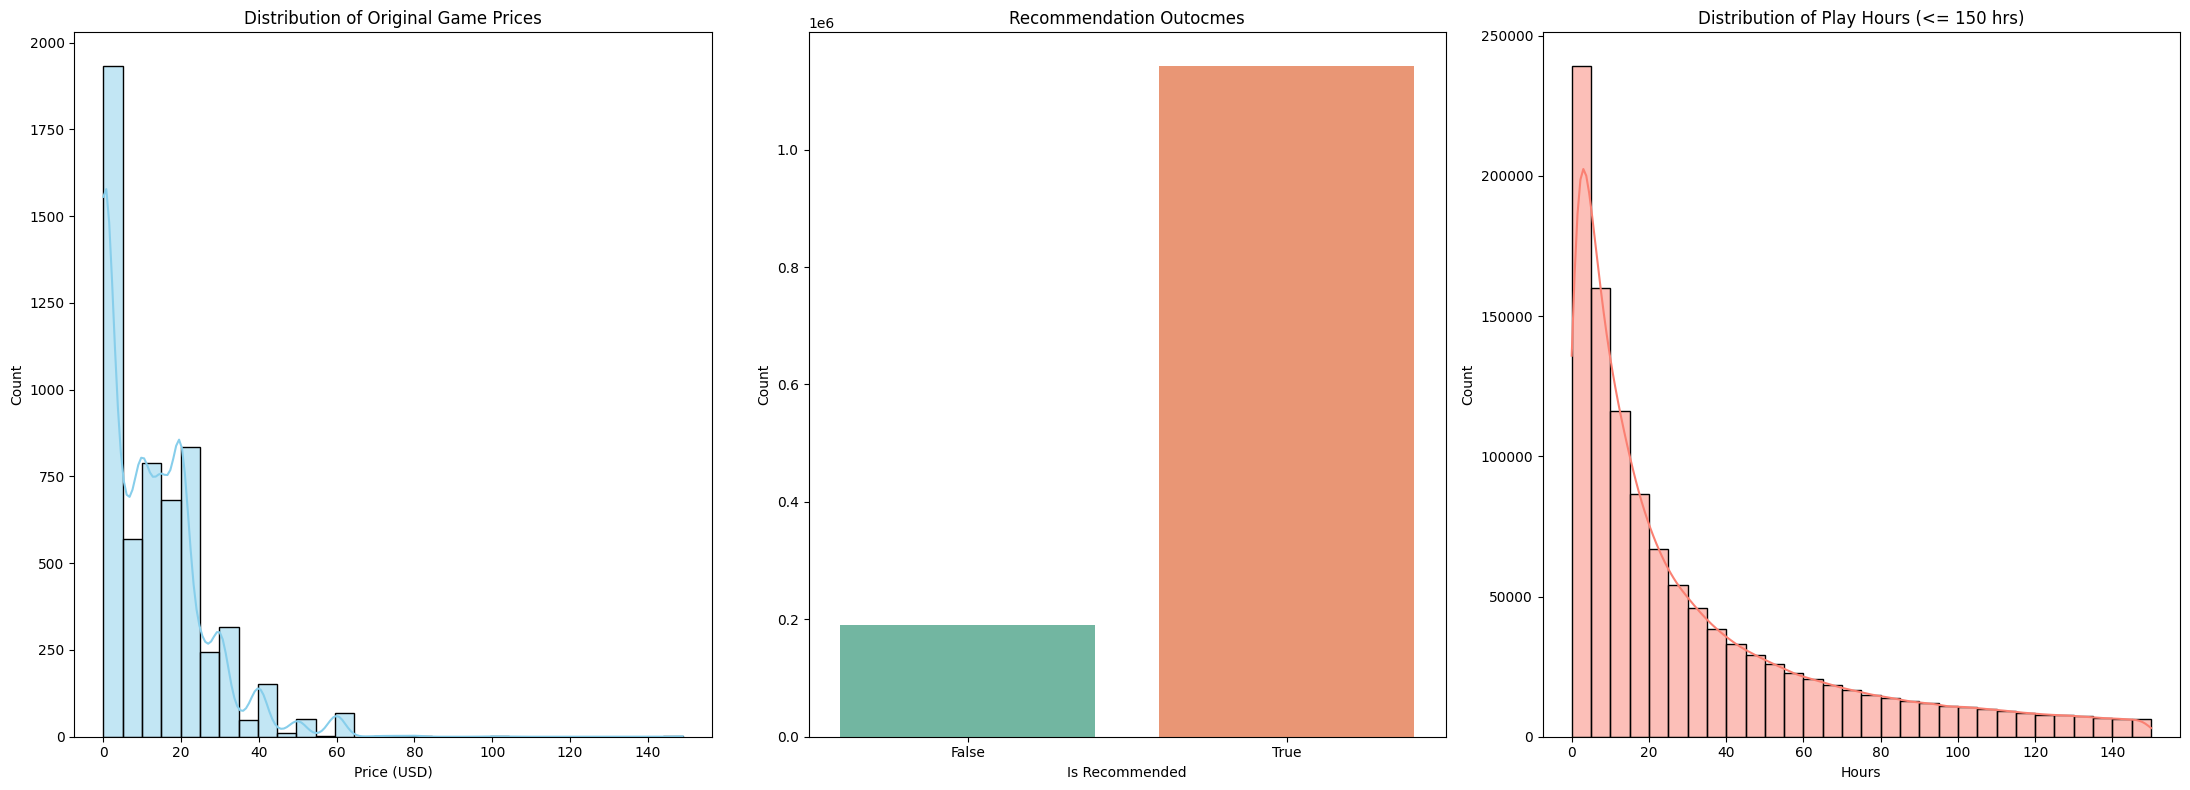

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(22, 8))

# 1. Distribution of Game Prices (Original Price)
sns.histplot(ax=axes[0], data=games, x='price_original', bins=30, kde=True, color='skyblue')
axes[0].set_title('Distribution of Original Game Prices')
axes[0].set_xlabel('Price (USD)')
axes[0].set_ylabel('Count')

# 2. Ratio of Recommended vs Not Recommended games
sns.countplot(ax=axes[1], data=recommendations, x='is_recommended', palette='Set2', hue='is_recommended', legend=False)
axes[1].set_title('Recommendation Outcomes')
axes[1].set_xlabel('Is Recommended')
axes[1].set_ylabel('Count')

# 3. Distribution of Hours Played in Sampled Reviews (Filtered outliers > 150 hours for visualization)
sns.histplot(ax=axes[2], data=recommendations[recommendations['hours'] <= 150], x='hours', bins=30, kde=True, color='salmon')
axes[2].set_title('Distribution of Play Hours (<= 150 hrs)')
axes[2].set_xlabel('Hours')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

## 5. Relationships & Key Metrics

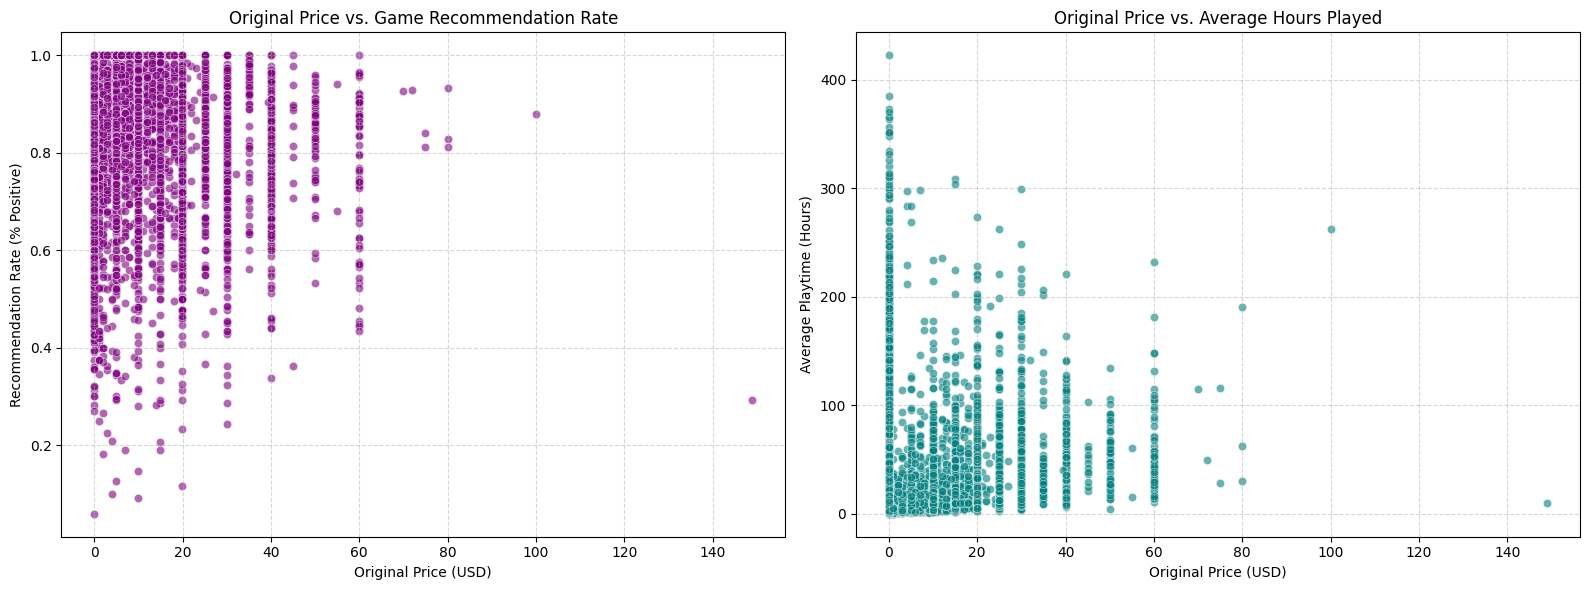

In [41]:
# Join games with recommendation metrics to explore price vs. recommendation behavior

# Calculate recommendation rate and average play hours per game
game_stats = recommendations.groupby('app_id').agg(
    recommend_rate=('is_recommended', 'mean'),
    avg_hours=('hours', 'mean'),
    review_count=('review_id', 'count')
).reset_index()

merged_df = pd.merge(games, game_stats, on='app_id')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Relationship between Game Price and Recommendation Rate (for games with >= 20 reviews to ensure stability)
sns.scatterplot(ax=axes[0], data=merged_df[merged_df['review_count'] >= 20], x='price_original', y='recommend_rate', alpha=0.6, color='purple')
axes[0].set_title('Original Price vs. Game Recommendation Rate')
axes[0].set_xlabel('Original Price (USD)')
axes[0].set_ylabel('Recommendation Rate (% Positive)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Relationship between Game Price and Average Hours Played
sns.scatterplot(ax=axes[1], data=merged_df[merged_df['review_count'] >= 20], x='price_original', y='avg_hours', alpha=0.6, color='teal')
axes[1].set_title('Original Price vs. Average Hours Played')
axes[1].set_xlabel('Original Price (USD)')
axes[1].set_ylabel('Average Playtime (Hours)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 5.1 Pricing Relationships by Price Tier

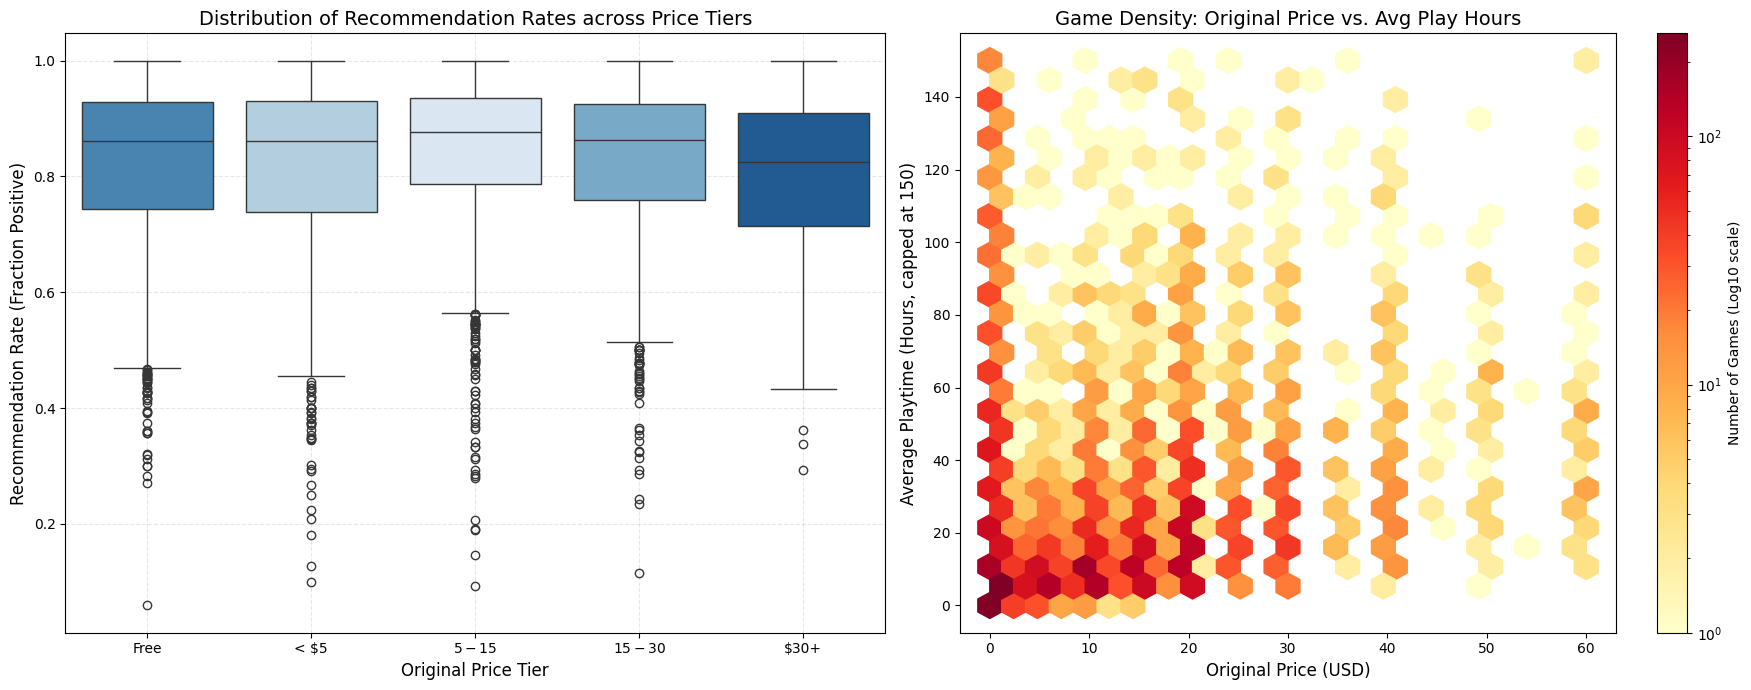

In [42]:
# Define distinct price tiers for categorical analysis
def categorize_price(price):
    if price == 0:
        return 'Free'
    elif price <= 4.99:
        return '< $5'
    elif price <= 14.99:
        return '$5 - $15'
    elif price <= 29.99:
        return '$15 - $30'
    else:
        return '$30+'

merged_df['price_tier'] = merged_df['price_original'].apply(categorize_price)
tier_order = ['Free', '< $5', '$5 - $15', '$15 - $30', '$30+']

# Filter to games with at least 15 reviews for statistically stable rates
stable_games = merged_df[merged_df['review_count'] >= 15]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Visual A
sns.boxplot(
    ax=axes[0],
    data=stable_games,
    x='price_tier',
    y='recommend_rate',
    order=tier_order,
    palette='Blues',
    hue='price_tier',
    legend=False
)
axes[0].set_title('Distribution of Recommendation Rates across Price Tiers', fontsize=14)
axes[0].set_xlabel('Original Price Tier', fontsize=12)
axes[0].set_ylabel('Recommendation Rate (Fraction Positive)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.3)

# Visual B
hb = axes[1].hexbin(
    stable_games['price_original'],
    stable_games['avg_hours'],
    gridsize=25,
    cmap='YlOrRd',
    bins='log',
    extent=[0, 60, 0, 150] # Focus on the bulk of pricing and hours
)
fig.colorbar(hb, ax=axes[1], label='Number of Games (Log10 scale)')
axes[1].set_title('Game Density: Original Price vs. Avg Play Hours', fontsize=14)
axes[1].set_xlabel('Original Price (USD)', fontsize=12)
axes[1].set_ylabel('Average Playtime (Hours, capped at 150)', fontsize=12)

plt.tight_layout()
plt.show()

## 6. Platform Compatibility Distribution (Windows, macOS, Linux)

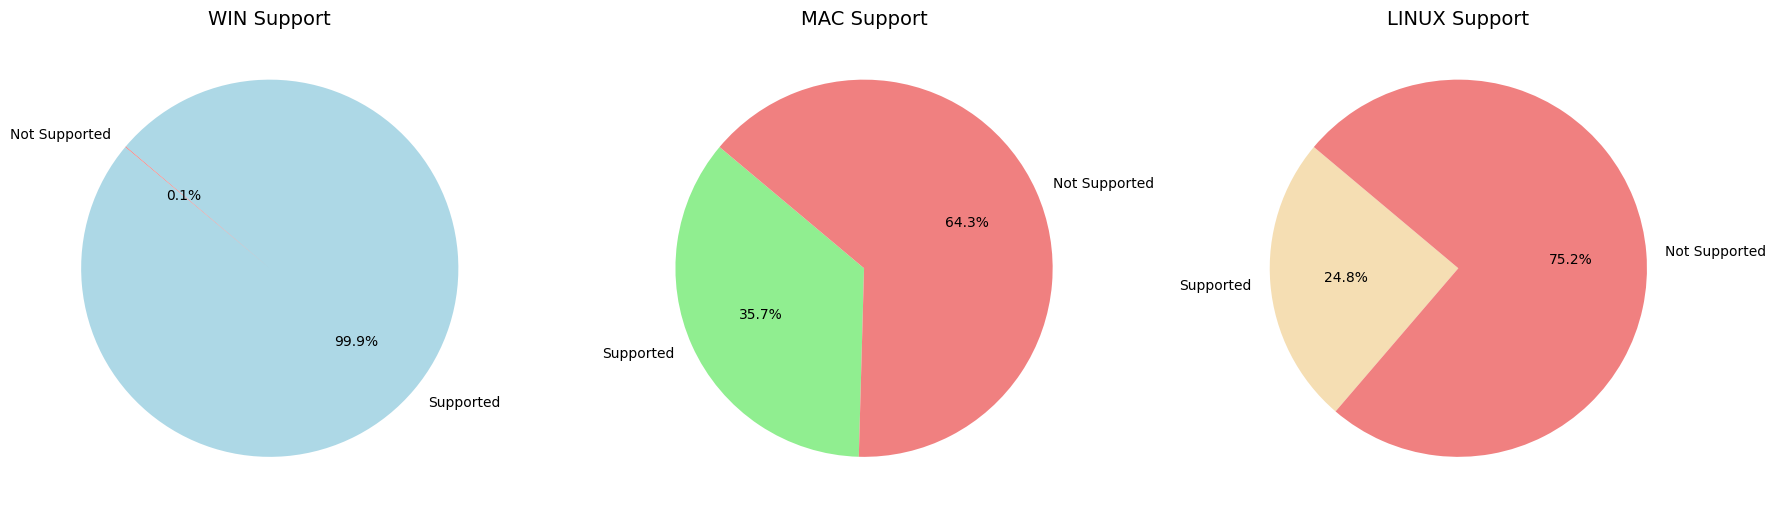

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

platforms = ['win', 'mac', 'linux']
colors = [['lightblue', 'lightcoral'], ['lightgreen', 'lightcoral'], ['wheat', 'lightcoral']]
labels = ['Supported', 'Not Supported']

for i, platform in enumerate(platforms):
    counts = games[platform].value_counts()
    sizes = [counts.get(True, 0), counts.get(False, 0)]

    axes[i].pie(
        sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors[i]
    )
    axes[i].set_title(f"{platform.upper()} Support", fontsize=14)

plt.tight_layout()
plt.show()

## 7. Correlation Between Features

In [44]:
# games
games.corr(numeric_only=True)

,app_id,win,mac,linux,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck
app_id,1.000000,0.009279,-0.194643,-0.211603,0.097201,-0.038546,0.087307,0.022560,-0.064669,0.012600
win,0.009279,1.000000,0.019713,0.015215,-0.029459,0.001014,0.027823,0.026025,0.007328,-0.000350
mac,-0.194643,0.019713,1.000000,0.644085,0.144489,0.026900,-0.123831,-0.105333,0.023501,0.009854
linux,-0.211603,0.015215,0.644085,1.000000,0.121777,0.033476,-0.087281,-0.073091,0.006948,0.007606
positive_ratio,0.097201,-0.029459,0.144489,0.121777,1.000000,0.029962,0.003318,-0.051667,-0.042502,-0.010404
user_reviews,-0.038546,0.001014,0.026900,0.033476,0.029962,1.000000,0.025969,-0.074804,-0.020869,0.000373
price_final,0.087307,0.027823,-0.123831,-0.087281,0.003318,0.025969,1.000000,0.699176,-0.175565,-0.020903
price_original,0.022560,0.026025,-0.105333,-0.073091,-0.051667,-0.074804,0.699176,1.000000,0.128369,-0.023275
discount,-0.064669,0.007328,0.023501,0.006948,-0.042502,-0.020869,-0.175565,0.128369,1.000000,0.003663
steam_deck,0.012600,-0.000350,0.009854,0.007606,-0.010404,0.000373,-0.020903,-0.023275,0.003663,1.000000


In [45]:
# recommendations
recommendations.drop(columns=['user_id', 'review_id', 'app_id']).corr(numeric_only=True)

,helpful,funny,is_recommended,hours
helpful,1.000000,0.561908,-0.024613,0.011792
funny,0.561908,1.000000,-0.002131,0.006442
is_recommended,-0.024613,-0.002131,1.000000,0.044039
hours,0.011792,0.006442,0.044039,1.000000


In [46]:
# users
users.corr(numeric_only=True)

,user_id,products,reviews
user_id,1.000000,0.058147,0.013081
products,0.058147,1.000000,0.208994
reviews,0.013081,0.208994,1.000000


## 8. Combined Correlation Matrix (All Three Tables)

In [47]:
id_cols = ['app_id', 'user_id', 'review_id']

combined_df = pd.merge(recommendations, games, on='app_id', suffixes=('_rec', '_game'))
combined_df = pd.merge(combined_df, users, on='user_id', suffixes=('_rec', '_user'))

combined_corr = combined_df.drop(columns=id_cols).corr(numeric_only=True)
display(combined_corr)

,helpful,funny,is_recommended,hours,win,mac,linux,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck,products,reviews
helpful,1.000000,0.586156,-0.025726,0.011567,-0.000880,-0.006232,-0.004467,-0.014491,0.015179,0.009685,0.002463,-0.001786,0.000228,0.041045,0.012237
funny,0.586156,1.000000,-0.001920,0.006811,0.000454,-0.001696,-0.000160,-0.001451,0.009538,0.002158,-0.003293,-0.001749,-0.003043,0.008670,0.001685
is_recommended,-0.025726,-0.001920,1.000000,0.044972,-0.007156,0.075936,0.069949,0.318596,-0.024460,-0.001434,-0.015169,0.002726,-0.003568,-0.040203,-0.070839
hours,0.011567,0.006811,0.044972,1.000000,0.012155,0.042399,0.040226,-0.000824,0.264946,0.047591,-0.159509,-0.074053,0.004258,-0.052874,-0.064925
win,-0.000880,0.000454,-0.007156,0.012155,1.000000,0.018377,0.014452,-0.021771,0.006705,0.026201,0.014728,0.005047,-0.000314,-0.010982,-0.000714
mac,-0.006232,-0.001696,0.075936,0.042399,0.018377,1.000000,0.683413,0.251941,0.087560,-0.179081,-0.095244,0.046728,0.011324,0.011183,0.011103
linux,-0.004467,-0.000160,0.069949,0.040226,0.014452,0.683413,1.000000,0.235157,0.106446,-0.160600,-0.035366,0.054235,0.008905,0.017370,0.013098
positive_ratio,-0.014491,-0.001451,0.318596,-0.000824,-0.021771,0.251941,0.235157,1.000000,0.018796,-0.019208,-0.109066,-0.011933,-0.008127,-0.023984,-0.027690
user_reviews,0.015179,0.009538,-0.024460,0.264946,0.006705,0.087560,0.106446,0.018796,1.000000,-0.045947,-0.176985,-0.057918,0.004111,-0.045179,-0.038353
price_final,0.009685,0.002158,-0.001434,0.047591,0.026201,-0.179081,-0.160600,-0.019208,-0.045947,1.000000,0.200764,-0.179994,-0.013644,-0.009387,-0.043423


## 9. Correlation Heatmap of Combined Data

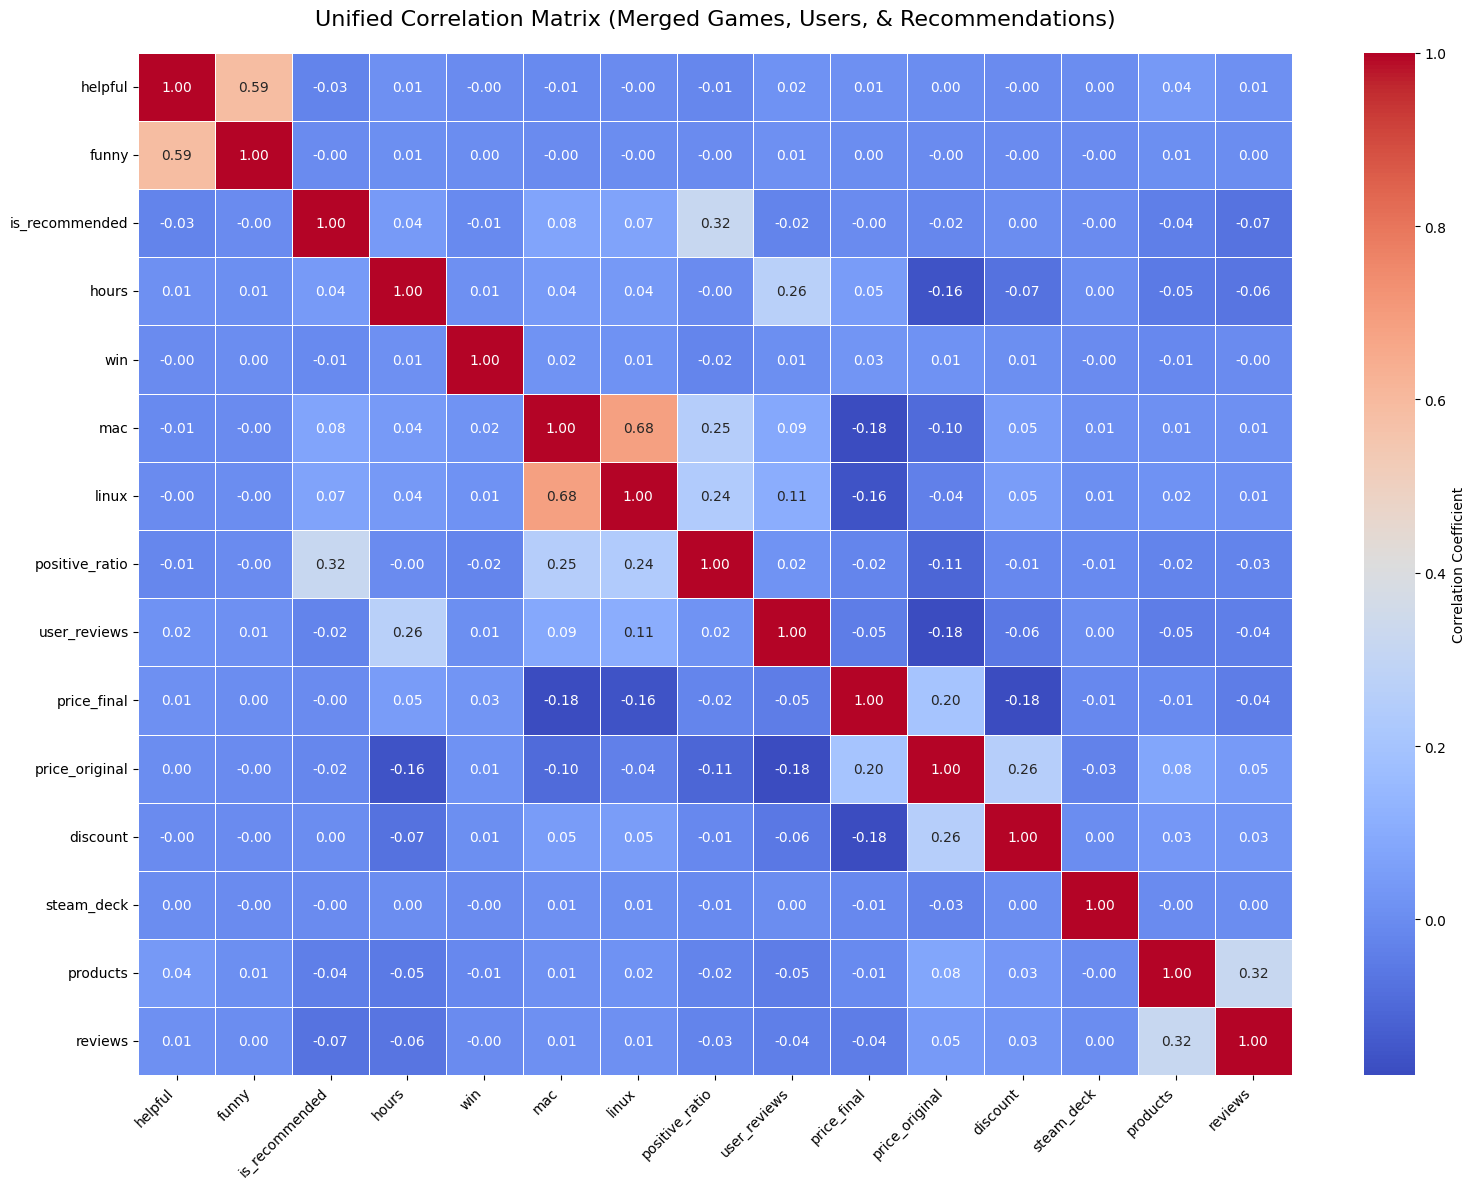

In [48]:
plt.figure(figsize=(16, 12))
sns.heatmap(
    combined_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    cbar_kws={'label': 'Correlation Coefficient'}
)
plt.title('Unified Correlation Matrix (Merged Games, Users, & Recommendations)', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Playtime by Recommendation Status

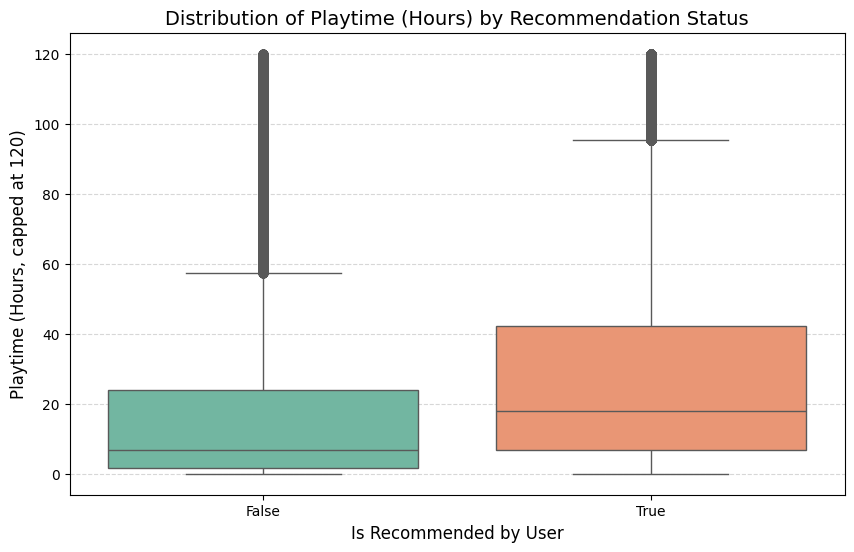

In [49]:
plt.figure(figsize=(10, 6))
# Filter extreme playtime outliers (> 120 hours) for visual clarity
filtered_combined = combined_df[combined_df['hours'] <= 120]

sns.boxplot(
    data=filtered_combined,
    x='is_recommended',
    y='hours',
    palette='Set2',
    hue='is_recommended',
    legend=False
)
plt.title('Distribution of Playtime (Hours) by Recommendation Status', fontsize=14)
plt.xlabel('Is Recommended by User', fontsize=12)
plt.ylabel('Playtime (Hours, capped at 120)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

## 11. Recommendation Rate by Supported Platform

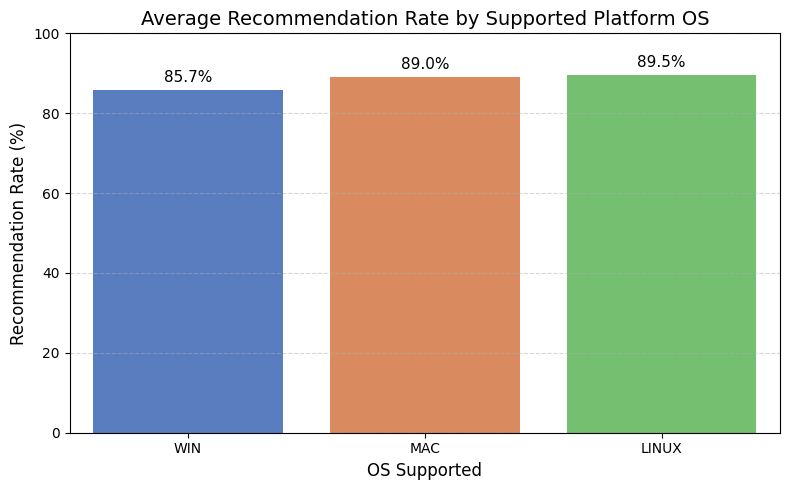

In [50]:
platform_stats = []
for plat in ['win', 'mac', 'linux']:
    supported_df = combined_df[combined_df[plat] == True]
    rec_rate = supported_df['is_recommended'].mean() * 100
    platform_stats.append({'Platform': plat.upper(), 'Recommendation Rate (%)': rec_rate})

platform_df = pd.DataFrame(platform_stats)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=platform_df,
    x='Platform',
    y='Recommendation Rate (%)',
    palette='muted',
    hue='Platform',
    legend=False
)
plt.title('Average Recommendation Rate by Supported Platform OS', fontsize=14)
plt.xlabel('OS Supported', fontsize=12)
plt.ylabel('Recommendation Rate (%)', fontsize=12)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for index, row in platform_df.iterrows():
    plt.text(index, row['Recommendation Rate (%)'] + 2, f"{row['Recommendation Rate (%)']:.1f}%", ha='center', fontsize=11)

plt.tight_layout()
plt.show()

## 12. Game Metadata (Tags & Descriptions)

In [54]:
metadata.shape

(5711, 5)

In [55]:
metadata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5711 entries, 0 to 5710
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   app_id           5711 non-null   int64 
 1   description      5711 non-null   object
 2   tags             5711 non-null   object
 3   desc_word_count  5711 non-null   int64 
 4   num_tags         5711 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 223.2+ KB


In [56]:
metadata.sample(5)

,app_id,description,tags,desc_word_count,num_tags
1929,1227280,Guide puny humans through Despot's Game - a ro...,"[Auto Battler, Pixel Graphics, Tactical, Rogue...",28,20
1780,485980,Real Time Strategy with a high degree of reali...,"[Real Time Tactics, RTS, Realistic, Military, ...",17,20
2083,1378290,"The Citadel is a brutal first person shooter, ...","[FPS, Retro, Indie, Gore, Old School, Violent,...",48,20
4485,391460,Free to play shooter about the confrontation o...,"[Free to Play, FPS, Multiplayer, Shooter, Acti...",40,20
2498,35140,Experience what it’s like to be Batman and fac...,"[Action, Stealth, Third Person, Superhero, Adv...",27,20


--- Description Word Count Summary ---
count    5711.000000
mean       31.754159
std        16.029727
min         0.000000
25%        22.000000
50%        35.000000
75%        44.000000
max        67.000000
Name: desc_word_count, dtype: float64

--- Tags per Game Summary ---
count    5711.000000
mean       15.713710
std         6.518583
min         0.000000
25%        13.000000
50%        20.000000
75%        20.000000
max        20.000000
Name: num_tags, dtype: float64


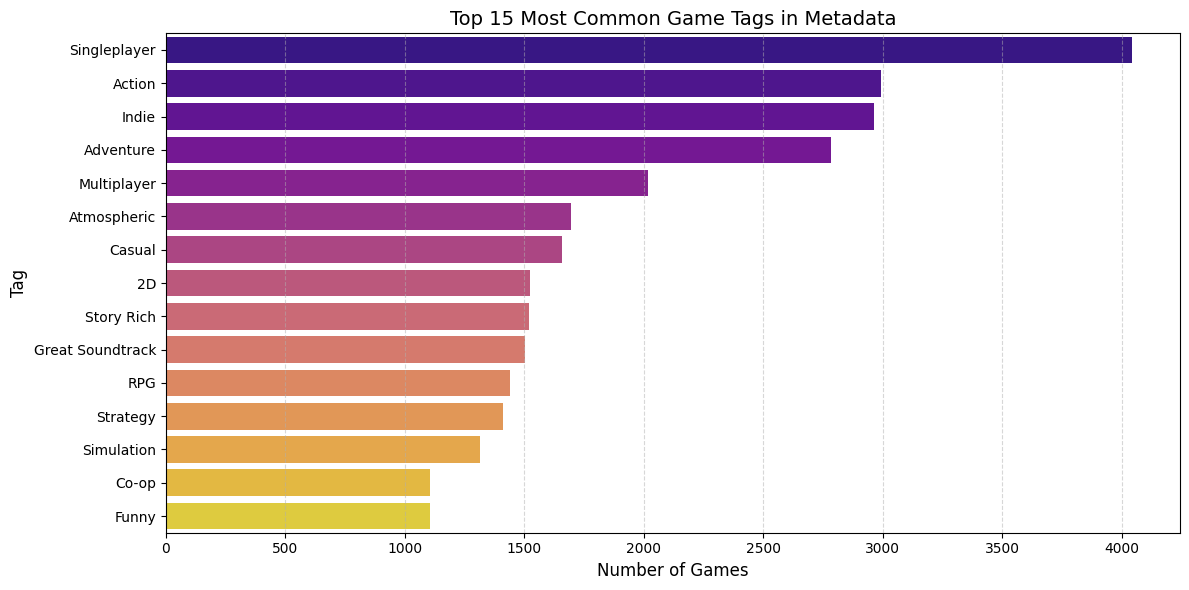

In [53]:
from collections import Counter

# 1. Basic Stats on Descriptions & Tags
metadata['desc_word_count'] = metadata['description'].fillna('').apply(lambda x: len(x.split()))
metadata['num_tags'] = metadata['tags'].apply(lambda x: len(x) if isinstance(x, list) else 0)

print("--- Description Word Count Summary ---")
print(metadata['desc_word_count'].describe())

print("\n--- Tags per Game Summary ---")
print(metadata['num_tags'].describe())

# Extract Most Common Tags
all_tags = []
for tags_list in metadata['tags'].dropna():
    if isinstance(tags_list, list):
        all_tags.extend(tags_list)

tag_counts = Counter(all_tags)
common_tags_df = pd.DataFrame(tag_counts.most_common(15), columns=['Tag', 'Frequency'])

# Visualize the Top 15 Tags
plt.figure(figsize=(12, 6))
sns.barplot(
    data=common_tags_df,
    x='Frequency',
    y='Tag',
    palette='plasma',
    hue='Tag',
    legend=False
)
plt.title('Top 15 Most Common Game Tags in Metadata', fontsize=14)
plt.xlabel('Number of Games', fontsize=12)
plt.ylabel('Tag', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Key Findings and Modelling Decisions

- **Implicit feedback.** There are no star ratings, only a thumbs up/down and playtime. The task is framed as ranking
  games a user has not reviewed yet, not as predicting a rating.
- **Very sparse matrix (~99.9%).** Collaborative filtering on a sparse user x game matrix (item-KNN, ALS) fits well.
- **Short histories.** The median user has about 4 reviews, so cold start matters. Tags and descriptions are used for a
  content-based model and for "similar games".
- **86% positive reviews.** Liked games are the positive signal. Disliked games are excluded from recommendations,
  not treated as training positives.
- **Playtime is informative but heavy-tailed.** It is used as a confidence weight, `1 + log1p(hours)`.
- **Timestamps exist.** Each user's most recent reviews are held out for validation and testing (temporal split),
  so the model is always evaluated on the future.
- **Weak linear correlations** between game attributes and recommendation, so a feature-based classifier is not the
  starting point. Interaction patterns carry the signal.
